# Prática — Rede Neural com as imagens de NDVI
## Prevendo o NDVI de cada pixel da bacia do Pirajibu-Mirim

**Pergunta da prática:** sabendo o NDVI de um pixel nos **3 meses anteriores**, uma rede neural consegue prever o NDVI desse pixel **neste mês**?

Agora cada **pixel** (10 m × 10 m) vira um exemplo. Isso gera milhares de exemplos, bem mais do que a média mensal da bacia.

**Ao final teremos um mapa do erro da rede:** os lugares onde ela mais errou costumam ser lugares onde **algo mudou de forma inesperada**.

## Etapa 1 — Instalar a biblioteca de leitura de imagens e conectar ao Drive

In [13]:
!pip install -q rasterio

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Etapa 2 — Configuração
Confira o **nome do GeoTIFF de NDVI** e o **mês da primeira banda**.

In [14]:
ARQUIVO = '/content/drive/MyDrive/Export-earth-engine/Pirajibu/NDVI_mensal.tif'

PRIMEIRO_MES = '2023-01'   # mês da banda 1
ANO_CORTE = 2024           # meses antes de 2024 = treino (70%); de 2024 em diante = teste (30%)
N_PIXELS = 3000            # quantos pixels sortear para treinar a rede

## Etapa 3 — Abrir a imagem
A imagem é um "cubo": **meses × linhas × colunas**. Cada banda é um mês.

In [15]:
import numpy as np
import pandas as pd
import rasterio

with rasterio.open(ARQUIVO) as src:
    cubo = src.read().astype('float32')        # (meses, linhas, colunas)
    nodata = src.nodata
    nomes_bandas = src.descriptions

if nodata is not None:
    cubo[cubo == nodata] = np.nan

n_meses, n_lin, n_col = cubo.shape
datas = pd.date_range(PRIMEIRO_MES, periods=n_meses, freq='MS')

print('Meses (bandas):', n_meses, '| de', datas[0].strftime('%m/%Y'), 'a', datas[-1].strftime('%m/%Y'))
print('Tamanho de cada mês:', n_lin, 'x', n_col, 'pixels')
print('Nomes das 3 primeiras bandas:', nomes_bandas[:3])

Meses (bandas): 36 | de 01/2023 a 12/2025
Tamanho de cada mês: 1574 x 1041 pixels
Nomes das 3 primeiras bandas: ('NDVI_2023_01', 'NDVI_2023_02', 'NDVI_2023_03')


## Etapa 4 — Olhar a imagem antes de qualquer modelo
Compare um mês chuvoso e um mês seco. Áreas em branco são pixels sem dado (fora da bacia ou com nuvem).

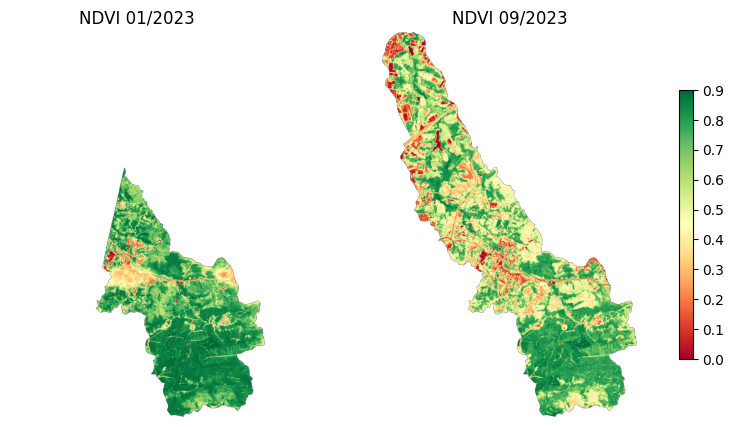

In [16]:
import matplotlib.pyplot as plt

mes_a, mes_b = 0, 8    # índices das bandas para comparar (0 = primeiro mês)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for eixo, i in zip(ax, [mes_a, mes_b]):
    im = eixo.imshow(cubo[i], cmap='RdYlGn', vmin=0, vmax=0.9)
    eixo.set_title('NDVI ' + datas[i].strftime('%m/%Y'))
    eixo.axis('off')
fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()

## Etapa 5 — Transformar pixels em exemplos
Para cada pixel sorteado e cada mês, montamos uma linha:

| Entradas | Saída |
|---|---|
| NDVI do pixel 3, 2 e 1 meses antes | NDVI do pixel no mês atual |

Linhas com algum valor vazio (nuvem, fora da bacia) são descartadas.

In [17]:
rng = np.random.default_rng(0)

# pixels com dado em pelo menos metade dos meses
validos = np.argwhere(np.isfinite(cubo).sum(axis=0) >= n_meses / 2)
sorteio = validos[rng.choice(len(validos), size=min(N_PIXELS, len(validos)), replace=False)]

linhas = []
for lin, col in sorteio:
    serie = cubo[:, lin, col]
    for t in range(3, n_meses):
        linhas.append([lin, col, datas[t], serie[t-3], serie[t-2], serie[t-1], serie[t]])

exemplos = pd.DataFrame(linhas, columns=['lin', 'col', 'data',
                                         'NDVI_3m', 'NDVI_2m', 'NDVI_1m', 'NDVI_alvo']).dropna()
ENTRADAS = ['NDVI_3m', 'NDVI_2m', 'NDVI_1m']

print('Total de exemplos:', len(exemplos))
exemplos.head()

Total de exemplos: 91275


,lin,col,data,NDVI_3m,NDVI_2m,NDVI_1m,NDVI_alvo
1,603,235,2023-05-01,0.291724,0.845075,0.859123,0.843157
2,603,235,2023-06-01,0.845075,0.859123,0.843157,0.695109
3,603,235,2023-07-01,0.859123,0.843157,0.695109,0.601578
4,603,235,2023-08-01,0.843157,0.695109,0.601578,0.762208
5,603,235,2023-09-01,0.695109,0.601578,0.762208,0.803273


## Etapa 6 — Um neurônio "à mão"
**saída = peso₁ × NDVI_3m + peso₂ × NDVI_2m + peso₃ × NDVI_1m + viés**

Mude os pesos e veja se a previsão se aproxima do real. A rede fará isso sozinha, ajustando os pesos pelo erro.

In [18]:
p3, p2, p1, vies = 0.0, 0.0, 1.0, 0.0     # <- experimente mudar

ex = exemplos.iloc[100]
previsao = p3 * ex['NDVI_3m'] + p2 * ex['NDVI_2m'] + p1 * ex['NDVI_1m'] + vies

print(f"Pixel (linha {ex['lin']}, coluna {ex['col']}) em {ex['data']:%m/%Y}")
print(f'Previsão do neurônio: {previsao:.3f}')
print(f"NDVI real:            {ex['NDVI_alvo']:.3f}")

Pixel (linha 640, coluna 437) em 11/2023
Previsão do neurônio: 0.630
NDVI real:            0.581


## Etapa 7 — Treinar a rede neural
A rede estuda os meses anteriores a 2024 e é testada nos meses de 2024 em diante.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

treino = exemplos[exemplos['data'].dt.year <  ANO_CORTE]
teste  = exemplos[exemplos['data'].dt.year >= ANO_CORTE]
print('Exemplos de treino:', len(treino), '| de teste:', len(teste))

escala = StandardScaler().fit(treino[ENTRADAS])

rede = MLPRegressor(hidden_layer_sizes=(8,), activation='tanh',
                    max_iter=300, early_stopping=True, random_state=0)
rede.fit(escala.transform(treino[ENTRADAS]), treino['NDVI_alvo'])
print('Rede treinada em', rede.n_iter_, 'épocas')

Exemplos de treino: 25855 | de teste: 65420
Rede treinada em 108 épocas


## Etapa 8 — A rede é melhor que a regra simples?
**Regra simples:** "o NDVI deste mês é igual ao do mês passado". Quanto menor o erro médio (MAE), melhor.

Erro médio da REDE NEURAL:   0.0721
Erro médio da REGRA SIMPLES: 0.0767


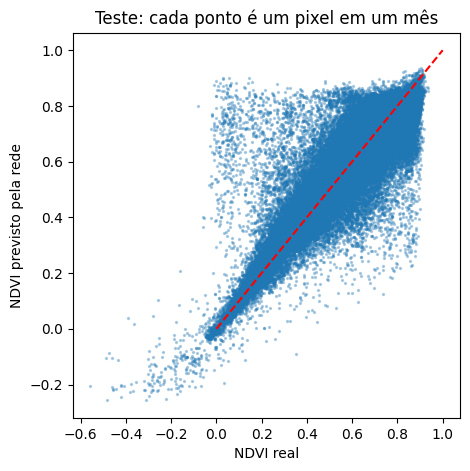

In [20]:
from sklearn.metrics import mean_absolute_error

prev_rede = rede.predict(escala.transform(teste[ENTRADAS]))

print(f"Erro médio da REDE NEURAL:   {mean_absolute_error(teste['NDVI_alvo'], prev_rede):.4f}")
print(f"Erro médio da REGRA SIMPLES: {mean_absolute_error(teste['NDVI_alvo'], teste['NDVI_1m']):.4f}")

plt.figure(figsize=(5, 5))
plt.scatter(teste['NDVI_alvo'], prev_rede, s=2, alpha=0.3)
plt.plot([0, 1], [0, 1], 'r--')
plt.xlabel('NDVI real'); plt.ylabel('NDVI previsto pela rede')
plt.title('Teste: cada ponto é um pixel em um mês')
plt.show()

## Etapa 9 — Mapa: onde a rede errou?
Agora a rede prevê **todos os pixels** de um mês do período de teste.
Erro **negativo** (vermelho) = o NDVI ficou **abaixo** do esperado: perda de vegetação, colheita, seca, nuvem mal mascarada...

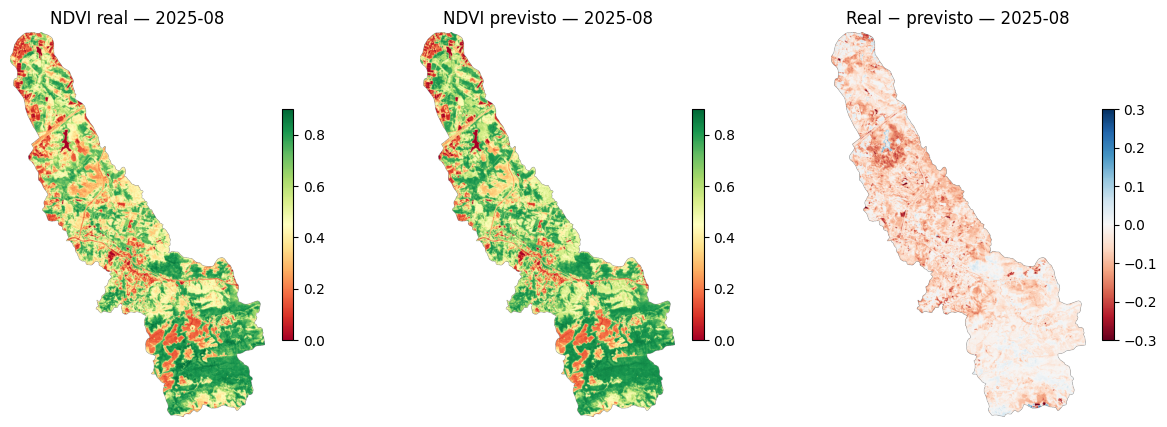

In [21]:
MES_MAPA = '2025-08'                      # <- escolha um mês do período de teste
t = datas.get_loc(pd.Timestamp(MES_MAPA))

X = np.stack([cubo[t-3], cubo[t-2], cubo[t-1]], axis=-1).reshape(-1, 3)
ok = np.isfinite(X).all(axis=1)

prevista = np.full(n_lin * n_col, np.nan, dtype='float32')
prevista[ok] = rede.predict(escala.transform(pd.DataFrame(X[ok], columns=ENTRADAS)))
prevista = prevista.reshape(n_lin, n_col)
erro = cubo[t] - prevista

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for eixo, img, tit, cmap, lim in [
        (ax[0], cubo[t], 'NDVI real', 'RdYlGn', (0, 0.9)),
        (ax[1], prevista, 'NDVI previsto', 'RdYlGn', (0, 0.9)),
        (ax[2], erro, 'Real − previsto', 'RdBu', (-0.3, 0.3))]:
    im = eixo.imshow(img, cmap=cmap, vmin=lim[0], vmax=lim[1])
    eixo.set_title(f'{tit} — {MES_MAPA}'); eixo.axis('off')
    fig.colorbar(im, ax=eixo, shrink=0.6)
plt.show()

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

prev_rede = rede.predict(escala.transform(teste[ENTRADAS]))
y_real = teste['NDVI_alvo']

mae  = mean_absolute_error(y_real, prev_rede)
rmse = np.sqrt(mean_squared_error(y_real, prev_rede))
r2   = r2_score(y_real, prev_rede)

print(f"MAE  (Erro Médio Absoluto):     {mae:.4f}")
print(f"RMSE (Raiz do Erro Quadrático): {rmse:.4f}")
print(f"R²   (Coef. de Determinação):   {r2:.4f}")

MAE  (Erro Médio Absoluto):     0.0721
RMSE (Raiz do Erro Quadrático): 0.1111
R²   (Coef. de Determinação):   0.7596


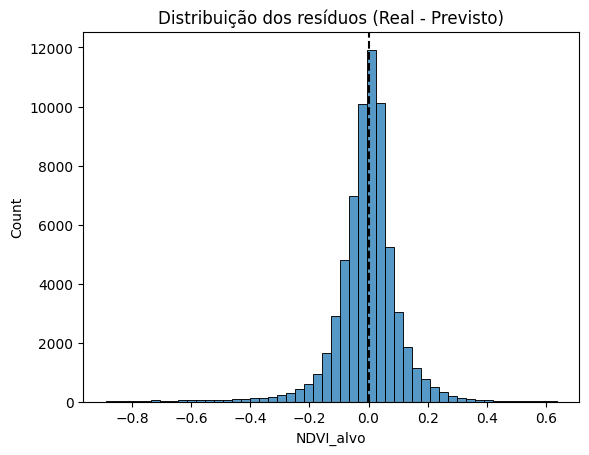

In [23]:
import seaborn as sns
residuos = y_real - prev_rede
sns.histplot(residuos, bins=50)
plt.axvline(0, color='black', linestyle='--')
plt.title('Distribuição dos resíduos (Real - Previsto)')
plt.show()